# 05 · Height validation against G-LiHT, by height class

**Question:** are reclassified 30 m heights closer to G-LiHT than the ATL08 · PhoREAL (today) segments, across height classes from tundra
shrubs to tall Kenai forest?

Reference for each segment: the 1 m G-LiHT CHM inside the segment footprint (30 m along track × 11 m), after the track's
horizontal shift from notebook 02. Main reference metric: CHM 98th percentile (RH98, config `validation.als_reference_percentile`);
RH90–RH100 are also compared because the best-matching ALS percentile for ICESat-2 is not fixed (Zhang & Liu 2023 found RH95).
Segments with > 10 % disturbed photons (Hansen loss in or after the ALS year) are excluded. Seward segments (UAV reference,
notebook 01) are added for the 0–2 m classes.

### Terms used in this notebook (same in every notebook of this series)

**Photons and their classes**
| Term | What it is |
|---|---|
| **ATL03 v007 photons** | Every photon ICESat-2 recorded (signal and solar background), with height and position. Nothing is classified yet. "v007" is the NASA data release; every version below uses release 007. |
| **ATL08 v007 photon classes** | NASA's labels for those photons (noise / ground / canopy / top of canopy), from the ATL08 product. Our current training data are built from these. |
| **Reclassified photon classes** | Our own labels for the **same** photons, from `lib/icesat2_photon_lib.py: reclassify` with the thresholds of one config version (`config/atl03_reclass_v0.N.yaml`). |
| **Reference photon labels** | Labels from airborne lidar (G-LiHT) or UAV surface models: a photon at the reference ground is ground, between ground and the reference canopy top is canopy, far above or below is noise. Treated as the truth. |

**30 m segments: a name says whose photon classes, then who cut them into 30 m segments and computed the heights**
| | binned by SlideRule PhoREAL | binned by our code (`segment_metrics`) |
|---|---|---|
| **ATL08 v007 photon classes** | **ATL08 · PhoREAL (today)**: what our training files contain today | **ATL08 · our binning (control)**: same classes, our binning; any difference from "today" is binning, not classification |
| **reclassified photon classes** | (not made) | **reclassified v0.N**: the candidate product, config v0.N |

Comparing **today** with **reclassified v0.N** is the result that matters; the **control** shows how much of that difference
comes from binning alone. Earlier notebooks and LOG entries called these "current v7 30 m", "ATL08 classes → our 30 m (check)"
and "reclassified photons → our 30 m (new)".

`h_canopy` = 98th percentile of canopy-photon heights above the ground in a 30 m segment (as in ATL08).
**Reference height** of a segment = 98th percentile of the 1 m reference canopy height model (G-LiHT or UAV) inside the segment's footprint (30 m along track × 11 m).

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)

REPO = Path.cwd().resolve().parents[1]          # notebooks/atl03_reclass -> repo root
sys.path.insert(0, str(REPO / "lib"))
import icesat2_photon_lib as ipl, reference_lib as ref, validation_lib as val, plot_style as ps
ps.apply()   # shared figure style; vegetation-height colormap ps.HEIGHT_CMAP; ESRI Light Gray basemap ps.add_basemap

cfg = ipl.load_config(REPO / "config" / "atl03_reclass_v0.6.yaml")   # profile auto: 'maap' on MAAP ADE, else 'adapt'
WORK = Path(cfg["paths"]["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)   # shared inputs: downloads, fetched photons, inventories
RUN = WORK / "runs" / f"v{cfg['version']}"; RUN.mkdir(parents=True, exist_ok=True)   # everything that depends on the config version
FIG = RUN / "figures"; FIG.mkdir(exist_ok=True)
print("profile:", cfg["profile"], "| config", cfg["version"], cfg["config_sha1"], "| work_dir:", WORK, "| run_dir:", RUN)
print(json.dumps(ipl.provenance(cfg), indent=1))

profile: adapt | config 0.6 40e8f82a4112 | work_dir: /explore/nobackup/people/pmontesa/atl03_reclass | run_dir: /explore/nobackup/people/pmontesa/atl03_reclass/runs/v0.6


{
 "repo": "circumpolar_boreal_trends",
 "git_commit": "0cecd4e",
 "git_dirty_lib_or_config": true,
 "config_version": "0.6",
 "config_sha1": "40e8f82a4112",
 "sliderule_client": "5.6.3",
 "processed_utc": "2026-10-18T04:42:20"
}


## Reference height for every segment

**Input:** the matched segments (notebook 04), the G-LiHT CHM strips and the track shifts (notebook 02).

**What happens:** each segment becomes a footprint rectangle (first to last photon, 11 m wide), shifted by its track's
horizontal offset; the 1 m CHM values inside it give the **reference height** (CHM RH98) and other percentiles and cover
fractions (`lib: segment_footprints, als_segment_metrics`). Segments with more than 10 % disturbed photons are dropped.
Seward segments (UAV reference, notebook 01) are added.

**Output:** `validation/tile_<n>_segments_als.parquet`.

In [2]:
GL = WORK / "glihit"; GLV = RUN / "glihit"; SEG = RUN / "segments"; OUT = RUN / "validation"; OUT.mkdir(exist_ok=True)
parts = []
for fn in sorted(SEG.glob("tile_*_segments.parquet")):
    t = int(fn.name.split("_")[1])
    s = gpd.read_parquet(fn)
    fpo = OUT / f"tile_{t}_segments_als.parquet"
    if fpo.exists():
        parts.append(gpd.read_parquet(fpo)); continue
    strips = pd.read_csv(GL / f"tile_{t}" / "strips.csv")
    off = pd.read_csv(GLV / f"tile_{t}" / "offsets.csv").set_index("track_id")
    fps = ref.segment_footprints(s, cfg["validation"]["segment_footprint_width_m"])
    out = []
    for tid, g in fps.groupby("track_id"):
        dx, dy = (off.loc[tid, "dx"], off.loc[tid, "dy"]) if tid in off.index else (0.0, 0.0)
        out.append(ref.als_segment_metrics(g, strips.chm.tolist(), dx, dy, percentiles=(50, 75, 90, 95, 98, 100)))
    a = gpd.GeoDataFrame(pd.concat(out), crs=fps.crs).to_crs(4326)
    ipl.write_parquet(a, fpo, ipl.provenance(cfg, tile_num=t))
    parts.append(a)
v = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs=4326)
v = v[(v.als_n > 0) & (v.disturbed_frac.fillna(0) <= 0.10)]
sew = pd.concat([gpd.read_parquet(f) for f in sorted((RUN / "seward").glob("*_segments.parquet"))], ignore_index=True)
sew = sew[sew.als_n > 0].assign(region="Seward")
val_all = pd.concat([v, sew], ignore_index=True)
print(val_all.groupby("region").size())

region
Interior    18833
Kenai        7313
Seward        494
dtype: int64


## Which G-LiHT height percentile does each version track?

`h_canopy` is the 98th percentile of canopy photons, but sparse photons rarely hit the very top of the canopy, so ICESat-2
heights may match a lower percentile of the lidar CHM (Zhang & Liu 2023 found RH95). Bias, RMSE and correlation of each 30 m
version against the CHM RH90, RH95, RH98 and RH100 inside the segment footprints.

In [3]:
schemes = {val.LABEL_CURRENT: "h_canopy_phoreal", val.LABEL_CHECK: "h_canopy_atl08", val.LABEL_NEW: "h_canopy"}
rows = []
for k, c in schemes.items():
    for p in (90, 95, 98, 100):
        d = val_all[[c, f"als_rh{p}"]].dropna()
        e = d[c] - d[f"als_rh{p}"]
        rows.append({"scheme": k, "als": f"RH{p}", "n": len(d), "bias": e.mean(), "rmse": np.sqrt((e ** 2).mean()), "r2": val.r_squared(d.iloc[:, 0], d.iloc[:, 1])})
pd.DataFrame(rows).pivot(index="als", columns="scheme", values=["bias", "rmse", "r2"]).round(2)

bias                                             \
scheme ATL08 · PhoREAL (today) ATL08 · our binning (control) reclassified   
als                                                                         
RH100                    -1.04                          0.87        -1.43   
RH90                      1.35                          3.56         0.75   
RH95                      0.69                          2.81         0.15   
RH98                      0.03                          2.07        -0.44   

                          rmse                                             \
scheme ATL08 · PhoREAL (today) ATL08 · our binning (control) reclassified   
als                                                                         
RH100                     8.03                          7.98         5.79   
RH90                      7.26                          7.72         4.98   
RH95                      7.34                          7.66         5.06   
RH98                      7.54                          7.72         5.25   

                            r2                                             
scheme ATL08 · PhoREAL (today) ATL08 · our binning (control) reclassified  
als                                                                        
RH100                     0.19                          0.15         0.48  
RH90                      0.21                          0.19         0.53  
RH95                      0.21                          0.18         0.52  
RH98                      0.20                          0.17         0.51

## Error by reference height class (reference height = G-LiHT/UAV CHM RH98 in the footprint)

Top: each 30 m version against the reference height. Bottom: mean bias and RMSE per reference-height class, and the
spurious-vegetation rate (reference < 1 m, ICESat-2 > 2 m). In the reclassified version, segments set to 0 m by the
short-vegetation guard count as 0 m here.

n   bias    rmse    mae  \
scheme                        height_class                                      
ATL08 · PhoREAL (today)       0-1 m              1042.0  3.283   8.967  3.381   
                              1-2 m               255.0  1.587   4.724  2.377   
                              2-5 m               398.0  0.683   5.269  2.696   
                              5-10 m              360.0 -1.220   5.657  3.566   
                              10-15 m             263.0 -3.712   5.787  4.554   
                              15-20 m             281.0 -5.108   7.562  5.826   
                              20+ m               133.0 -8.669  11.778  8.905   
                              all                2732.0  0.034   7.541  3.845   
                              spurious_veg_rate  1042.0  0.372     NaN    NaN   
ATL08 · our binning (control) 0-1 m               654.0  7.335   9.980  7.356   
                              1-2 m               224.0  5.498  10.690  5.720   
                              2-5 m               391.0  2.168   5.482  3.422   
                              5-10 m              330.0  0.420   4.820  3.605   
                              10-15 m             255.0 -2.149   4.840  3.666   
                              15-20 m             275.0 -3.566   5.475  4.052   
                              20+ m               129.0 -6.292   8.894  6.487   
                              all                2258.0  2.070   7.720  5.096   
                              spurious_veg_rate   654.0  0.693     NaN    NaN   
reclassified                  0-1 m               678.0  1.159   5.047  1.497   
                              1-2 m               208.0  0.958   6.473  2.527   
                              2-5 m               282.0 -0.835   3.868  2.681   
                              5-10 m              185.0 -1.830   5.296  4.031   
                              10-15 m             166.0 -2.473   5.280  3.701   
                              15-20 m             181.0 -2.883   6.060  4.181   
                              20+ m                70.0 -3.618   5.536  3.996   
                              all                1770.0 -0.438   5.251  2.652   
                              spurious_veg_rate   678.0  0.134     NaN    NaN   

                                                 ref_mean  est_mean  
scheme                        height_class                           
ATL08 · PhoREAL (today)       0-1 m                 0.220     3.503  
                              1-2 m                 1.409     2.997  
                              2-5 m                 3.522     4.205  
                              5-10 m                7.048     5.828  
                              10-15 m              12.611     8.899  
                              15-20 m              17.322    12.213  
                              20+ m                22.576    13.907  
                              all                   5.752     5.786  
                              spurious_veg_rate       NaN       NaN  
ATL08 · our binning (control) 0-1 m                 0.294     7.629  
                              1-2 m                 1.427     6.925  
                              2-5 m                 3.486     5.653  
                              5-10 m                7.094     7.513  
                              10-15 m              12.663    10.514  
                              15-20 m              17.313    13.747  
                              20+ m                22.552    16.260  
                              all                   6.694     8.764  
                              spurious_veg_rate       NaN       NaN  
reclassified                  0-1 m                 0.241     1.400  
                              1-2 m                 1.397     2.355  
                              2-5 m                 3.475     2.640  
                              5-10 m                7.123     5.293  
                        

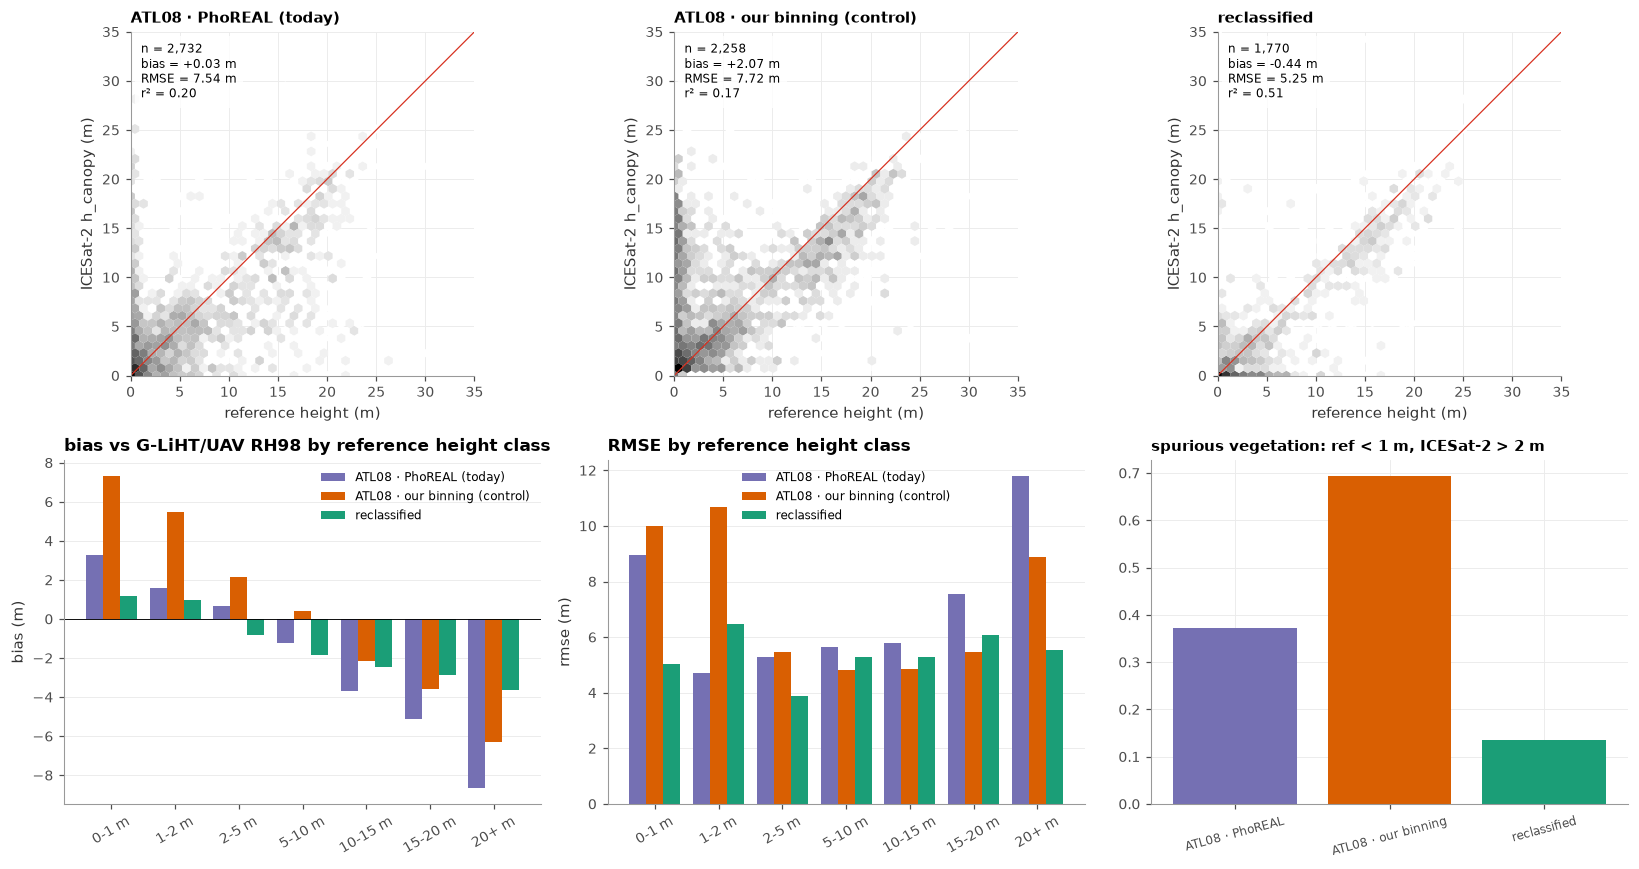

In [4]:
edges = cfg["validation"]["height_classes_m"]
REF = f"als_rh{cfg['validation']['als_reference_percentile']}"
tabs = {k: val.metrics_by_height_class(val_all[c], val_all[REF], edges, cfg["validation"]["spurious_veg"]) for k, c in schemes.items()}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (k, c) in zip(axes[0], schemes.items()):
    val.plot_scatter(ax, val_all[c], val_all[REF], k, lim=35)
val.plot_bias_by_class(tabs, f"bias vs G-LiHT/UAV {REF.upper()[4:]} by reference height class", axes[1, 0], "bias")
val.plot_bias_by_class(tabs, "RMSE by reference height class", axes[1, 1], "rmse")
sp = pd.Series({k: t.loc["spurious_veg_rate", "bias"] for k, t in tabs.items()})
axes[1, 2].bar(range(len(sp)), sp.values, color=[val.SCHEME_COLORS[k] for k in sp.index])
axes[1, 2].set_xticks(range(len(sp)), [k.split(" (")[0] for k in sp.index], rotation=15, fontsize=8)
axes[1, 2].set_title("spurious vegetation: ref < 1 m, ICESat-2 > 2 m", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "05_height_validation.png", dpi=150)
summary = pd.concat(tabs, names=["scheme", "height_class"]).round(3)
summary.to_csv(OUT / "height_validation_by_class.csv")
summary

## By region, day vs night, and beam strength

Mean bias of each 30 m version against the reference height, split by region (Interior, Kenai, Seward), by solar elevation,
and by beam strength.

bias                                \
scheme          ATL08 · PhoREAL (today) ATL08 · our binning (control)   
by     group                                                            
beam   strong                      0.42                          1.53   
       weak                       -0.65                          3.07   
light  day                        -0.46                          3.01   
       night                       1.14                         -0.15   
region Interior                   -0.04                          2.46   
       Kenai                      -0.40                          0.65   
       Seward                      1.82                          4.82   

                                                rmse  \
scheme          reclassified ATL08 · PhoREAL (today)   
by     group                                           
beam   strong          -0.18                    6.87   
       weak            -1.88                    8.59   
light  day             -0.44                    6.24   
       night           -0.43                    9.84   
region Interior        -0.68                    5.75   
       Kenai           -0.69                    9.47   
       Seward           0.98                    3.41   

                                                            
scheme          ATL08 · our binning (control) reclassified  
by     group                                                
beam   strong                            6.55         5.24  
       weak                              9.51         5.29  
light  day                               8.19         5.21  
       night                             6.47         5.33  
region Interior                          7.36         5.18  
       Kenai                             8.05         5.22  
       Seward                            7.56         5.52

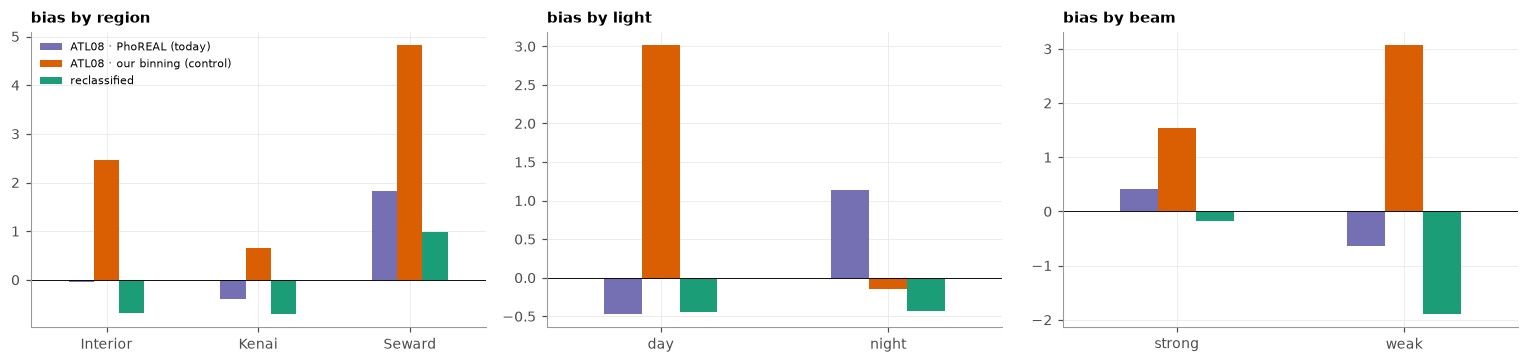

In [5]:
val_all["light"] = np.where(val_all.solar_elevation > 0, "day", "night")
val_all["beam"] = np.where(val_all.strong, "strong", "weak")
rows = []
for by in ["region", "light", "beam"]:
    for grp, g in val_all.groupby(by):
        for k, c in schemes.items():
            d = g[[c, REF]].dropna(); e = d[c] - d[REF]
            rows.append({"by": by, "group": grp, "scheme": k, "n": len(d), "bias": e.mean(), "rmse": np.sqrt((e ** 2).mean())})
t = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, by in zip(axes, ["region", "light", "beam"]):
    tt = t[t.by == by].pivot(index="group", columns="scheme", values="bias")
    tt.plot.bar(ax=ax, color=[val.SCHEME_COLORS[c] for c in tt.columns], legend=(by == "region"), rot=0)
    ax.axhline(0, c="k", lw=0.6); ax.set_title(f"bias by {by}", loc="left", fontsize=10); ax.set_xlabel("")
axes[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "05_bias_by_group.png", dpi=150)
t.pivot_table(index=["by", "group"], columns="scheme", values=["bias", "rmse"]).round(2)

## By signal strength: day/night × beam

The shift scan (LOG, 15 Oct) showed that footprint placement does not explain the low pooled agreement; signal does (r ≈ 0.6 at
night, ≈ 0.5 on strong beams). Every version is therefore also reported in the four signal strata: night strong, night weak,
day strong, day weak. A version that only looks good in the pooled numbers because of the mix of strata is not an improvement.

bias                                \
scheme         ATL08 · PhoREAL (today) ATL08 · our binning (control)   
stratum                                                                
night · strong                    1.92                          0.30   
night · weak                     -0.74                         -1.46   
day · strong                     -0.36                          2.17   
day · weak                       -0.62                          4.32   

                                                  n  \
scheme         reclassified ATL08 · PhoREAL (today)   
stratum                                               
night · strong        -0.27                   600.0   
night · weak          -1.40                   248.0   
day · strong          -0.14                  1138.0   
day · weak            -2.08                   746.0   

                                                           \
scheme         ATL08 · our binning (control) reclassified   
stratum                                                     
night · strong                         502.0        481.0   
night · weak                           172.0         77.0   
day · strong                           964.0       1022.0   
day · weak                             620.0        190.0   

                                    r2                                \
scheme         ATL08 · PhoREAL (today) ATL08 · our binning (control)   
stratum                                                                
night · strong                    0.23                          0.40   
night · weak                      0.07                          0.29   
day · strong                      0.40                          0.27   
day · weak                        0.07                          0.02   

                                               rmse  \
scheme         reclassified ATL08 · PhoREAL (today)   
stratum                                               
night · strong         0.54                    9.24   
night · weak           0.61                   11.15   
day · strong           0.52                    5.21   
day · weak             0.15                    7.54   

                                                           
scheme         ATL08 · our binning (control) reclassified  
stratum                                                    
night · strong                          6.40         5.61  
night · weak                            6.67         3.08  
day · strong                            6.63         5.06  
day · weak                             10.16         5.96

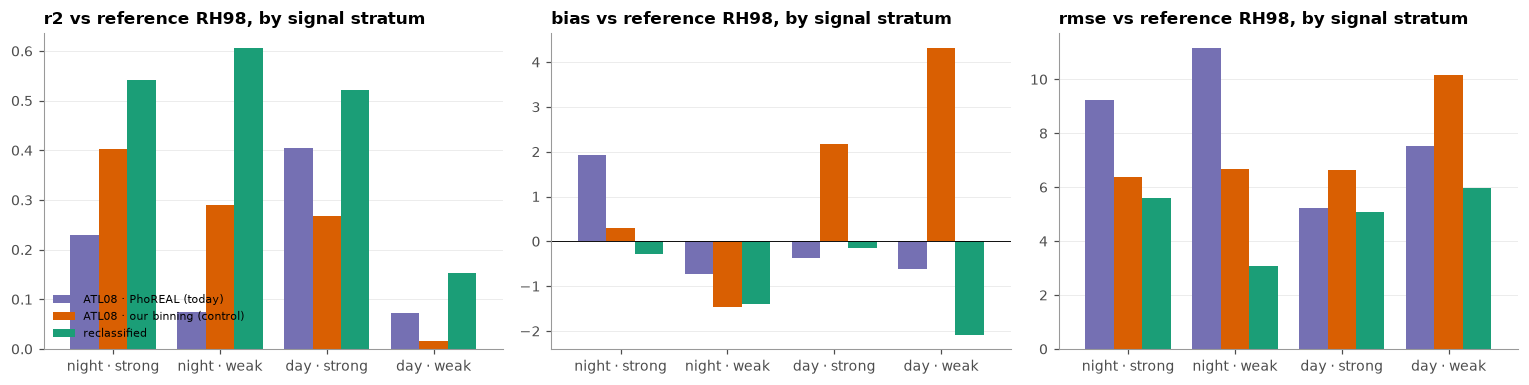

In [6]:
val_all["signal_stratum"] = val_all["light"] + " · " + val_all["beam"]
order = ["night · strong", "night · weak", "day · strong", "day · weak"]
rows = []
for st, g in val_all.groupby("signal_stratum"):
    for k, c in schemes.items():
        d = g[[c, REF]].dropna(); e = d[c] - d[REF]
        rows.append({"stratum": st, "scheme": k, "n": len(d), "bias": e.mean(), "rmse": np.sqrt((e ** 2).mean()),
                     "r2": val.r_squared(d.iloc[:, 0], d.iloc[:, 1])})
ts = pd.DataFrame(rows)
ts.to_csv(OUT / "height_validation_by_signal.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, m in zip(axes, ["r2", "bias", "rmse"]):
    tt = ts.pivot(index="stratum", columns="scheme", values=m).reindex(order)
    tt.plot.bar(ax=ax, color=[val.SCHEME_COLORS[c] for c in tt.columns], legend=(m == "r2"), rot=0, width=0.8)
    ax.axhline(0, c="k", lw=0.6); ax.set_title(f"{m} vs reference {REF.upper()[4:]}, by signal stratum"); ax.set_xlabel("")
    ax.grid(axis="x", visible=False)
axes[0].legend(fontsize=7, loc="lower left")
fig.tight_layout(); fig.savefig(FIG / "05_by_signal.png")
ts.pivot_table(index="stratum", columns="scheme", values=["n", "r2", "bias", "rmse"]).reindex(order).round(2)

## Compared with the previous config version, on common segments

Mean bias moves when a version reports heights for a different set of segments (for example v0.1 wrote 0 m where v0.2 reports
"not enough signal"), even if no height changed. So the previous version is compared here (a) on the segments **both** versions
report, by reference height class and region, and (b) by **coverage**: the share of segments that get a height at all.
Tall-forest acceptance (LOG, 15 Oct): in every class ≥ 10 m and every region, the new version's bias must be no more negative
than the ATL08 · PhoREAL (today).

coverage: share of segments with a height


,previous (v0.5),this version (v0.6),ATL08 · PhoREAL (today)
region,,,
Interior,0.622,0.623,0.939
Kenai,0.552,0.557,0.870


bias                  \
version               ATL08 · PhoREAL (today) previous (v0.5)   
region   height_class                                           
Interior 0-1 m                           2.06            0.90   
         1-2 m                           0.83           -0.19   
         10-15 m                        -4.70           -2.71   
         15-20 m                        -8.68           -6.47   
         2-5 m                          -0.55           -1.91   
         20+ m                         -10.62           -8.38   
         5-10 m                         -2.53           -3.39   
         all                            -0.07           -0.83   
Kenai    0-1 m                           3.55            1.33   
         1-2 m                           5.09            1.85   
         10-15 m                        -2.06           -2.26   
         15-20 m                        -3.58           -2.68   
         2-5 m                           1.67           -0.34   
         20+ m                          -6.25           -2.97   
         5-10 m                          0.46           -0.44   
         all                            -0.13           -0.75   
all      0-1 m                           2.74            1.09   
         1-2 m                           1.44            0.18   
         10-15 m                        -2.86           -2.40   
         15-20 m                        -3.99           -2.98   
         2-5 m                           0.16           -1.41   
         20+ m                          -6.66           -3.47   
         5-10 m                         -1.10           -1.95   
         all                            -0.10           -0.79   

                                                                n  \
version               this version (v0.6) ATL08 · PhoREAL (today)   
region   height_class                                               
Interior 0-1 m                       0.91                   276.0   
         1-2 m                       0.15                   120.0   
         10-15 m                    -2.68                    49.0   
         15-20 m                    -6.47                    14.0   
         2-5 m                      -1.86                   131.0   
         20+ m                      -8.38                     6.0   
         5-10 m                     -3.37                    90.0   
         all                        -0.76                   686.0   
Kenai    0-1 m                       1.39                   229.0   
         1-2 m                       1.87                    20.0   
         10-15 m                    -2.32                   113.0   
         15-20 m                    -2.47                   158.0   
         2-5 m                      -0.58                    62.0   
         20+ m                      -3.00                    57.0   
         5-10 m                     -0.42                    82.0   
         all                        -0.71                   721.0   
all      0-1 m                       1.12                   505.0   
         1-2 m                       0.47                   140.0   
         10-15 m                    -2.43                   162.0   
         15-20 m                    -2.79                   172.0   
         2-5 m                      -1.45                   193.0   
         20+ m                      -3.50                    63.0   
         5-10 m                     -1.93                   172.0   
         all                        -0.73                  1407.0   

                                                           \
version               previous (v0.5) this version (v0.6)   
region   height_class                                       
Interior 0-1 m                  299.0               299.0   
         1-2 m                  125.0               125.0   
         10-15 m                 49.0                49.0   
         15-20 m                 14.0                14

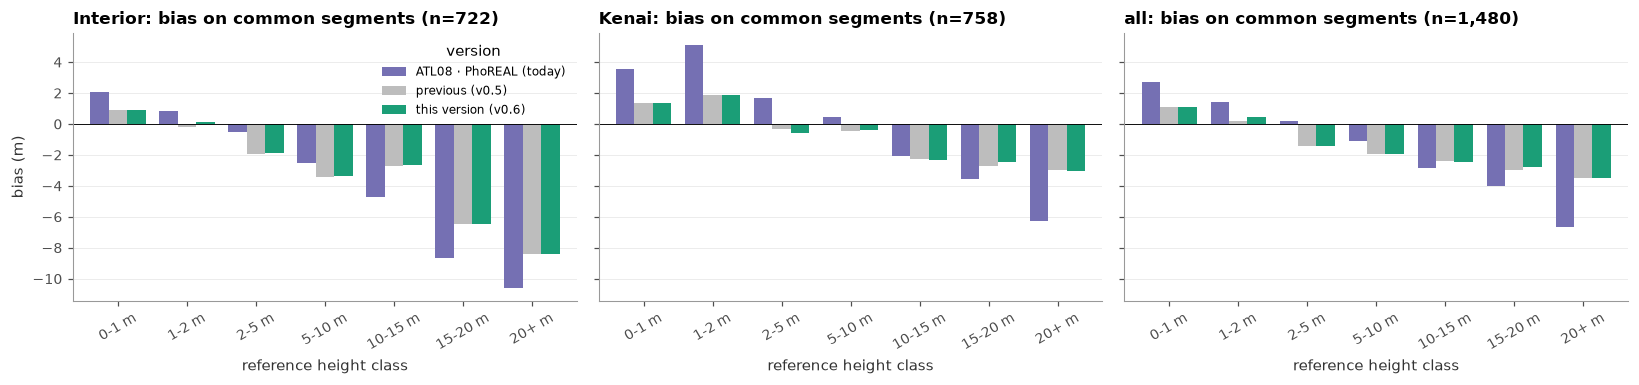

In [7]:
# previous version = the latest earlier run with G-LiHT validation outputs (v0.5 for v0.6; v0.3 was validated only on
# LVIS / CanElevation); v0.1 outputs predate runs/
_prev = sorted([p for p in (WORK / "runs").glob("v*") if p.name < f"v{cfg['version']}" and any((p / "validation").glob("tile_*_segments_als.parquet"))])
PREV = _prev[-1] / "validation" if _prev else WORK / "validation"
prev = pd.concat([gpd.read_parquet(f) for f in sorted(PREV.glob("tile_*_segments_als.parquet"))], ignore_index=True)
prev = prev[(prev.als_n > 0) & (prev.disturbed_frac.fillna(0) <= 0.10)]
key = ["track_id", "seg"]
cur = v[key + ["region", "h_canopy", REF, "h_canopy_phoreal", "solar_elevation", "strong"]]
both = cur.merge(prev[key + ["h_canopy"]].rename(columns={"h_canopy": "h_prev"}), on=key, how="inner")
lab_prev, lab_cur = f"previous ({PREV.parent.name if PREV.parent.name.startswith('v') else 'v0.1'})", f"this version (v{cfg['version']})"
cov = pd.DataFrame({lab_prev: prev.groupby("region").h_canopy.apply(lambda s: s.notna().mean()),
                    lab_cur: cur.groupby("region").h_canopy.apply(lambda s: s.notna().mean()),
                    "ATL08 · PhoREAL (today)": cur.groupby("region").h_canopy_phoreal.apply(lambda s: s.notna().mean())}).round(3)
print("coverage: share of segments with a height"); display(cov)
common = both.dropna(subset=["h_canopy", "h_prev", REF])
rows = []
for reg, g in list(common.groupby("region")) + [("all", common)]:
    for nm, col in [(lab_prev, "h_prev"), (lab_cur, "h_canopy"), ("ATL08 · PhoREAL (today)", "h_canopy_phoreal")]:
        t = val.metrics_by_height_class(g[col], g[REF], edges)
        rows.append(t.assign(region=reg, version=nm))
cmp_tab = pd.concat(rows).reset_index(names="height_class")
cmp_tab.to_csv(OUT / "version_comparison_common_segments.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, reg in zip(axes, ["Interior", "Kenai", "all"]):
    tt = cmp_tab[(cmp_tab.region == reg) & ~cmp_tab.height_class.isin(["all", "spurious_veg_rate"])]
    pv = tt.pivot(index="height_class", columns="version", values="bias").reindex(val.height_class_labels(edges))
    vcol = {lab_prev: "#bdbdbd", lab_cur: val.SCHEME_COLORS[val.LABEL_NEW], "ATL08 · PhoREAL (today)": val.SCHEME_COLORS[val.LABEL_CURRENT]}
    pv.plot.bar(ax=ax, rot=30, width=0.8, color=[vcol[c] for c in pv.columns])
    ax.axhline(0, c="k", lw=0.6); ax.set_title(f"{reg}: bias on common segments (n={int((common.region == reg).sum()) if reg != 'all' else len(common):,})")
    ax.set_xlabel("reference height class"); ax.set_ylabel("bias (m)"); ax.grid(axis="x", visible=False)
    if reg != "Interior": ax.get_legend().remove()
fig.tight_layout(); fig.savefig(FIG / "05_version_comparison.png")
cmp_tab.pivot_table(index=["region", "height_class"], columns="version", values=["n", "bias", "rmse"]).round(2)

## Results (config v0.6, 18 October 2026)

- **All segments with a G-LiHT reference** (RH98): r² today 0.20 → v0.6 0.51, RMSE 7.5 → 5.3 m, bias 0.0 → −0.4 m.
- **Same segments for every version** (notebook 11): spurious vegetation 30 → 10 %; short vegetation (< 2 m) +2.2 → +0.9 m;
  20 m+ forest −6.7 → −3.5 m; r² 0.39 → 0.56. Coverage Interior 94 → 62 %, Kenai 87 → 56 % (acceptable).
- **Tall-forest acceptance** (no more negative than today in every class ≥ 10 m and region): met in 5 of 6 cells (e.g.
  Interior 20 m+ −10.6 → −8.4 m on 6 segments; Kenai 20 m+ −6.3 → −3.0 m); Kenai 10–15 m misses by 0.3 m (−2.06 → −2.32 m).
  Mid-height forest (5–10 m) is more negative than today in both regions (Interior −2.5 → −3.4 m; Kenai +0.5 → −0.4 m).
- **Signal:** the largest remaining bias is on weak beams by day (−2.1 m, 190 segments); strong beams by day and night are
  within 0.3 m.
- **v0.5 → v0.6:** within 0.1 m in almost every class (coverage +0.5 points); v0.6's change matters under the denser
  canopy of the CanElevation boxes (notebook 10).